In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

DOSSIER_PROJET = Path(
    r"C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention"
)

DOSSIER_IMAGES = DOSSIER_PROJET / "archive" / "chest_xray"

DOSSIER_REPARTITION = (
    DOSSIER_PROJET
    / "repartitions"
    / "repartition_20260917_102959_713272"
)

train_df = pd.read_csv(DOSSIER_REPARTITION / "train.csv")

# Reconstruire les chemins à partir de l'emplacement des images.
train_df["chemin"] = train_df["chemin_relatif"].apply(
    lambda chemin: DOSSIER_IMAGES / chemin
)

fichiers_absents = train_df[
    ~train_df["chemin"].apply(lambda chemin: chemin.is_file())
]

if not fichiers_absents.empty:
    display(fichiers_absents[["chemin_relatif"]].head())
    raise FileNotFoundError(
        f"{len(fichiers_absents)} fichiers sont introuvables."
    )

print("Images d'apprentissage rechargées :", len(train_df))
display(train_df.groupby("classe").size().rename("Nombre d'images"))

Images d'apprentissage rechargées : 3800


classe
NORMAL       1079
PNEUMONIA    2721
Name: Nombre d'images, dtype: int64

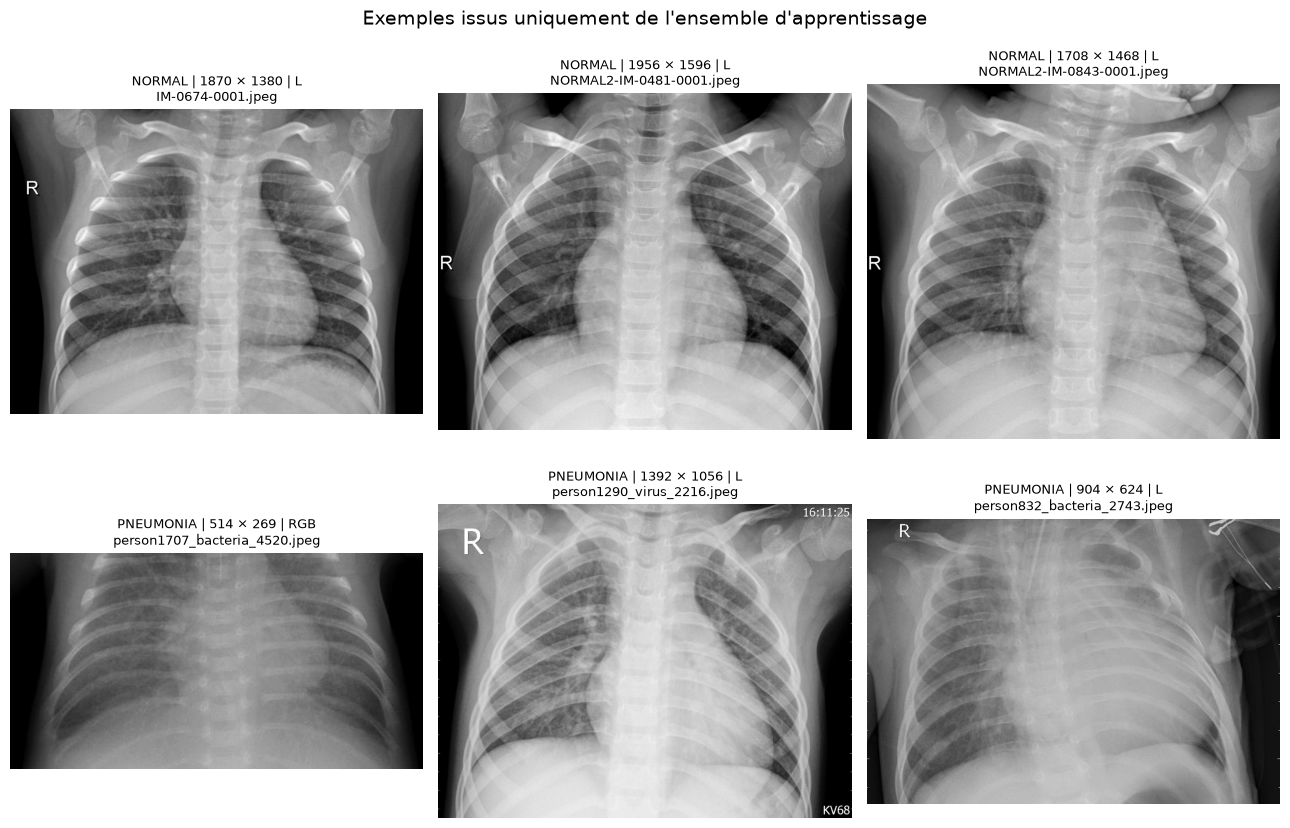

In [2]:
from PIL import Image
import matplotlib.pyplot as plt
import textwrap

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for ligne, classe in enumerate(["NORMAL", "PNEUMONIA"]):
    exemples = (
        train_df[train_df["classe"] == classe]
        .sample(n=3, random_state=42)
        .reset_index(drop=True)
    )

    for colonne, exemple in exemples.iterrows():
        with Image.open(exemple["chemin"]) as image:
            largeur, hauteur = image.size
            mode_original = image.mode

            # Conversion pour l'affichage uniquement.
            image_affichee = image.convert("RGB")

        axe = axes[ligne, colonne]
        axe.imshow(image_affichee)
        axe.set_title(
            f"{classe} | {largeur} × {hauteur} | {mode_original}\n"
            + textwrap.fill(exemple["nom"], width=32),
            fontsize=9
        )
        axe.axis("off")

plt.suptitle(
    "Exemples issus uniquement de l'ensemble d'apprentissage",
    fontsize=14
)
plt.tight_layout()
plt.show()

In [3]:
from PIL import Image, ImageOps

TAILLE_IMAGE = 224

def preparer_image(image):
    """Convertir en niveaux de gris et redimensionner avec bordures."""
    image_grise = image.convert("L")

    return ImageOps.pad(
        image_grise,
        size=(TAILLE_IMAGE, TAILLE_IMAGE),
        method=Image.Resampling.BILINEAR,
        color=0,
        centering=(0.5, 0.5)
    )

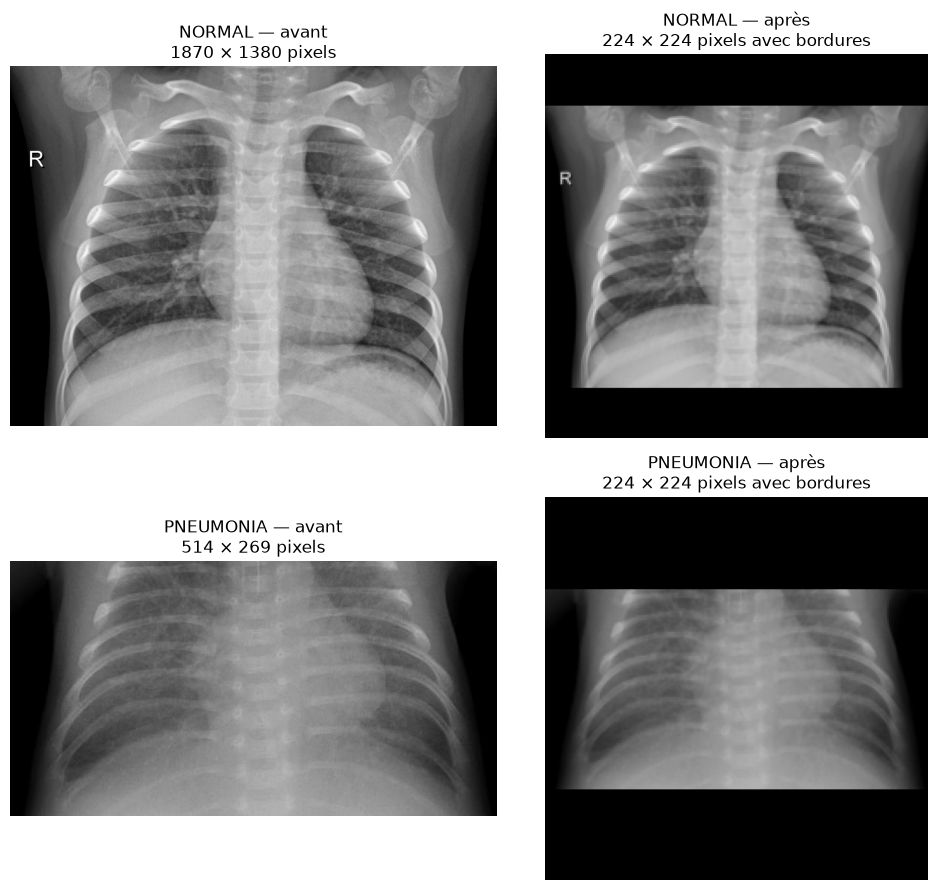

Vérification réussie : images de 224 × 224, en mode L.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

if "train_df" not in globals():
    raise RuntimeError(
        "Exécute d'abord la cellule qui recharge train.csv."
    )

# Une image de chaque classe, issue uniquement de l'apprentissage.
exemples = pd.concat(
    [
        train_df[train_df["classe"] == classe].sample(
            n=1, random_state=42
        )
        for classe in ["NORMAL", "PNEUMONIA"]
    ],
    ignore_index=True
)

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ligne, exemple in exemples.iterrows():
    with Image.open(exemple["chemin"]) as image:
        originale = image.convert("L")
        preparee = preparer_image(image)

    assert preparee.size == (224, 224)
    assert preparee.mode == "L"

    axes[ligne, 0].imshow(
        originale, cmap="gray", vmin=0, vmax=255
    )
    axes[ligne, 0].set_title(
        f"{exemple['classe']} — avant\n"
        f"{originale.width} × {originale.height} pixels"
    )

    axes[ligne, 1].imshow(
        preparee, cmap="gray", vmin=0, vmax=255
    )
    axes[ligne, 1].set_title(
        f"{exemple['classe']} — après\n"
        "224 × 224 pixels avec bordures"
    )

    for axe in axes[ligne]:
        axe.axis("off")

plt.tight_layout()
plt.show()

print("Vérification réussie : images de 224 × 224, en mode L.")

In [5]:
import numpy as np
import torch
from PIL import Image

if "preparer_image" not in globals() or "train_df" not in globals():
    raise RuntimeError(
        "Exécute d'abord les cellules de chargement et de préparation."
    )

def image_vers_tenseur(image):
    # Niveaux de gris, redimensionnement et bordures.
    image_preparee = preparer_image(image)

    # Tableau de nombres décimaux entre 0 et 1.
    tableau = np.array(image_preparee, dtype=np.float32) / 255.0

    # Passage de [hauteur, largeur] à [canal, hauteur, largeur].
    return torch.from_numpy(tableau).unsqueeze(0)

# Tester la conversion sur une image d'apprentissage.
exemple = train_df.iloc[0]

with Image.open(exemple["chemin"]) as image:
    tenseur = image_vers_tenseur(image)

print("Image :", exemple["nom"])
print("Classe :", exemple["classe"])
print("Dimensions du tenseur :", tenseur.shape)
print("Type numérique :", tenseur.dtype)
print("Valeur minimale :", tenseur.min().item())
print("Valeur maximale :", tenseur.max().item())

assert tenseur.shape == (1, 224, 224)
assert tenseur.dtype == torch.float32
assert torch.isfinite(tenseur).all()
assert 0.0 <= tenseur.min().item() <= tenseur.max().item() <= 1.0

print("\nConversion en tenseur réussie.")

Image : IM-0115-0001.jpeg
Classe : NORMAL
Dimensions du tenseur : torch.Size([1, 224, 224])
Type numérique : torch.float32
Valeur minimale : 0.0
Valeur maximale : 0.9725490212440491

Conversion en tenseur réussie.


In [6]:
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

if "image_vers_tenseur" not in globals():
    raise RuntimeError(
        "Exécute d'abord la cellule qui définit image_vers_tenseur."
    )

CLASSES = {"NORMAL": 0, "PNEUMONIA": 1}
TAILLE_LOT = 16

class RadiographiesDataset(Dataset):
    def __init__(self, fichier_csv, dossier_images, transformation):
        self.tableau = pd.read_csv(fichier_csv).reset_index(drop=True)
        self.dossier_images = dossier_images
        self.transformation = transformation

        if not self.tableau["classe"].isin(CLASSES).all():
            raise ValueError("Une classe inconnue figure dans le fichier CSV.")

    def __len__(self):
        return len(self.tableau)

    def __getitem__(self, indice):
        ligne = self.tableau.iloc[indice]
        chemin = self.dossier_images / ligne["chemin_relatif"]

        with Image.open(chemin) as image:
            tenseur = self.transformation(image)

        etiquette = torch.tensor(
            CLASSES[ligne["classe"]],
            dtype=torch.long
        )

        return tenseur, etiquette

train_dataset = RadiographiesDataset(
    DOSSIER_REPARTITION / "train.csv",
    DOSSIER_IMAGES,
    image_vers_tenseur
)

val_dataset = RadiographiesDataset(
    DOSSIER_REPARTITION / "val.csv",
    DOSSIER_IMAGES,
    image_vers_tenseur
)

print("Images d'apprentissage :", len(train_dataset))
print("Images de validation :", len(val_dataset))

Images d'apprentissage : 3800
Images de validation : 953


In [7]:
def creer_chargeurs(graine=42):
    # Générateur dédié au mélange des images d'apprentissage.
    generateur = torch.Generator().manual_seed(graine)

    train_loader = DataLoader(
        train_dataset,
        batch_size=TAILLE_LOT,
        shuffle=True,
        generator=generateur,
        num_workers=0,
        drop_last=False
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=TAILLE_LOT,
        shuffle=False,
        num_workers=0,
        drop_last=False
    )

    return train_loader, val_loader

train_loader, val_loader = creer_chargeurs()

print("Lots d'apprentissage :", len(train_loader))
print("Lots de validation :", len(val_loader))

images, etiquettes = next(iter(train_loader))

print("\nDimensions du lot :", images.shape)
print("Dimensions des étiquettes :", etiquettes.shape)
print("Type des images :", images.dtype)
print("Type des étiquettes :", etiquettes.dtype)
print("Étiquettes du lot :", etiquettes.tolist())

assert images.shape == (16, 1, 224, 224)
assert images.dtype == torch.float32
assert etiquettes.shape == (16,)
assert etiquettes.dtype == torch.long
assert torch.isfinite(images).all()
assert images.min().item() >= 0 and images.max().item() <= 1
assert set(etiquettes.tolist()).issubset({0, 1})

print("\nChargement du premier lot réussi.")

# Réinitialiser le mélange après cette vérification.
train_loader, val_loader = creer_chargeurs()

Lots d'apprentissage : 238
Lots de validation : 60

Dimensions du lot : torch.Size([16, 1, 224, 224])
Dimensions des étiquettes : torch.Size([16])
Type des images : torch.float32
Type des étiquettes : torch.int64
Étiquettes du lot : [0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1]

Chargement du premier lot réussi.


In [8]:
import torch
from torch import nn

class CNNClassique(nn.Module):
    def __init__(self):
        super().__init__()

        self.bloc1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.bloc2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.bloc3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.reduction = nn.AdaptiveAvgPool2d((4, 4))

        self.classificateur = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(64, 2)
        )

    def forward(self, images):
        x = self.bloc1(images)
        x = self.bloc2(x)
        x = self.bloc3(x)
        x = self.reduction(x)
        return self.classificateur(x)

# Fixer l'initialisation pour pouvoir reproduire cette expérience.
torch.manual_seed(42)

device = torch.device("cpu")
modele_cnn = CNNClassique().to(device)

nombre_parametres = sum(
    parametre.numel()
    for parametre in modele_cnn.parameters()
    if parametre.requires_grad
)

print("Matériel utilisé :", device)
print("Paramètres entraînables :", nombre_parametres)

Matériel utilisé : cpu
Paramètres entraînables : 89026


In [9]:
if "train_dataset" not in globals():
    raise RuntimeError("Exécute d'abord les cellules des Dataset et DataLoader.")

# Chargeur réservé à la vérification :
# il ne modifie pas l'ordre du chargeur d'apprentissage.
chargeur_verification = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

images_verification, etiquettes_verification = next(
    iter(chargeur_verification)
)

# Désactiver le dropout pour cette vérification.
modele_cnn.eval()

with torch.no_grad():
    scores = modele_cnn(images_verification.to(device))

assert scores.shape == (len(images_verification), 2)
assert torch.isfinite(scores).all()

print("Dimensions en entrée :", images_verification.shape)
print("Dimensions en sortie :", scores.shape)
print("Deux scores par image : NORMAL, puis PNEUMONIA.")
print("\nVérification du CNN réussie.")

# Remettre le modèle en mode apprentissage.
modele_cnn.train()

Dimensions en entrée : torch.Size([16, 1, 224, 224])
Dimensions en sortie : torch.Size([16, 2])
Deux scores par image : NORMAL, puis PNEUMONIA.

Vérification du CNN réussie.


CNNClassique(
  (bloc1): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bloc2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bloc3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (reduction): AdaptiveAvgPool2d(output_size=(4, 4))
  (classificateur): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

In [10]:
import torch
from torch import nn

# Ordre correspondant aux sorties du modèle : NORMAL=0, PNEUMONIA=1.
effectifs = (
    train_dataset.tableau["classe"]
    .value_counts()
    .reindex(["NORMAL", "PNEUMONIA"], fill_value=0)
)

if (effectifs == 0).any():
    raise ValueError("Une classe est absente de l'apprentissage.")

poids_classes = torch.tensor(
    [
        len(train_dataset) / (2 * effectifs["NORMAL"]),
        len(train_dataset) / (2 * effectifs["PNEUMONIA"])
    ],
    dtype=torch.float32,
    device=device
)

critere = nn.CrossEntropyLoss(weight=poids_classes)

TAUX_APPRENTISSAGE = 0.001

optimiseur = torch.optim.Adam(
    modele_cnn.parameters(),
    lr=TAUX_APPRENTISSAGE
)

print("Poids NORMAL :", round(poids_classes[0].item(), 6))
print("Poids PNEUMONIA :", round(poids_classes[1].item(), 6))
print("Taux d'apprentissage :", TAUX_APPRENTISSAGE)
print("Fonction de perte et optimiseur prêts.")

Poids NORMAL : 1.76089
Poids PNEUMONIA : 0.698273
Taux d'apprentissage : 0.001
Fonction de perte et optimiseur prêts.


In [11]:
modele_cnn.eval()

with torch.no_grad():
    scores = modele_cnn(images_verification.to(device))
    perte = critere(
        scores,
        etiquettes_verification.to(device)
    )

assert torch.isfinite(perte).item(), "La perte n'est pas un nombre fini."

print("Perte sur le lot de vérification :", round(perte.item(), 4))
print("Calcul de la perte réussi.")

# Le point-virgule évite l'affichage de toute l'architecture.
modele_cnn.train();

Perte sur le lot de vérification : 0.6845
Calcul de la perte réussi.


In [12]:
import time
import pandas as pd
import torch
from tqdm import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def executer_epoque(modele, chargeur, apprentissage=False):
    modele.train(apprentissage)

    somme_pertes = 0.0
    somme_poids = 0.0
    vraies_classes = []
    predictions = []

    description = "Apprentissage" if apprentissage else "Validation"

    for images, etiquettes in tqdm(chargeur, desc=description):
        images = images.to(device)
        etiquettes = etiquettes.to(device)

        if apprentissage:
            optimiseur.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(apprentissage):
            scores = modele(images)
            perte = critere(scores, etiquettes)

            if not torch.isfinite(perte).item():
                raise RuntimeError("Une perte non finie a été détectée.")

            if apprentissage:
                perte.backward()
                optimiseur.step()

        # Moyenne correcte pour notre CrossEntropyLoss pondérée.
        poids_lot = critere.weight[etiquettes].sum().item()
        somme_pertes += perte.item() * poids_lot
        somme_poids += poids_lot

        predictions.extend(scores.detach().argmax(dim=1).cpu().tolist())
        vraies_classes.extend(etiquettes.cpu().tolist())

    mesures = {
        "perte": somme_pertes / somme_poids,
        "exactitude": accuracy_score(vraies_classes, predictions),
        "precision_pneumonie": precision_score(
            vraies_classes, predictions, pos_label=1, zero_division=0
        ),
        "rappel_pneumonie": recall_score(
            vraies_classes, predictions, pos_label=1, zero_division=0
        ),
        "f1_pneumonie": f1_score(
            vraies_classes, predictions, pos_label=1, zero_division=0
        ),
        "f1_macro": f1_score(
            vraies_classes, predictions,
            labels=[0, 1], average="macro", zero_division=0
        )
    }

    matrice = confusion_matrix(
        vraies_classes, predictions, labels=[0, 1]
    )

    return mesures, matrice

print("Fonction prête.")

Fonction prête.


In [13]:
from datetime import datetime
from IPython.display import display

# Nouveau dossier pour cette expérience.
identifiant = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
DOSSIER_EXPERIENCE = (
    DOSSIER_PROJET / "experiences" / f"cnn_classique_{identifiant}"
)
DOSSIER_EXPERIENCE.mkdir(parents=True, exist_ok=False)

# Initialisation reproductible de cette première expérience.
torch.manual_seed(42)
modele_cnn = CNNClassique().to(device)
optimiseur = torch.optim.Adam(
    modele_cnn.parameters(),
    lr=TAUX_APPRENTISSAGE
)
train_loader, val_loader = creer_chargeurs(graine=42)

historique = []

def sauvegarder_etat(nom_fichier, epoque):
    etat = {
        "epoque": epoque,
        "modele": modele_cnn.state_dict(),
        "optimiseur": optimiseur.state_dict(),
        "poids_classes": poids_classes.cpu(),
        "historique": historique,
        "etat_aleatoire_torch": torch.get_rng_state(),
        "etat_generateur_train": train_loader.generator.get_state(),
        "dossier_repartition": str(DOSSIER_REPARTITION),
        "classes": CLASSES,
        "pretraitement": {
            "taille": 224,
            "mode": "L",
            "redimensionnement": "padding noir, bilineaire, centre",
            "echelle_pixels": "division par 255",
            "augmentation": False
        },
        "taille_lot": TAILLE_LOT,
        "version_torch": str(torch.__version__)
    }

    destination = DOSSIER_EXPERIENCE / nom_fichier
    temporaire = destination.with_suffix(".tmp")
    torch.save(etat, temporaire)
    temporaire.replace(destination)

# Garder aussi le point de départ.
sauvegarder_etat("initialisation.pt", epoque=0)

debut = time.perf_counter()

mesures_train, _ = executer_epoque(
    modele_cnn, train_loader, apprentissage=True
)

# Sauvegarde avant validation, au cas où celle-ci serait interrompue.
sauvegarder_etat("apres_apprentissage_epoque_1.pt", epoque=1)

mesures_val, matrice_val = executer_epoque(
    modele_cnn, val_loader, apprentissage=False
)

duree = time.perf_counter() - debut

ligne = {"epoque": 1, "duree_secondes": duree}
ligne.update({f"train_{cle}": valeur for cle, valeur in mesures_train.items()})
ligne.update({f"val_{cle}": valeur for cle, valeur in mesures_val.items()})
historique.append(ligne)

sauvegarder_etat("epoque_1.pt", epoque=1)

pd.DataFrame(historique).to_csv(
    DOSSIER_EXPERIENCE / "historique.csv",
    index=False
)

display(
    pd.DataFrame(
        [mesures_train, mesures_val],
        index=["Apprentissage", "Validation"]
    ).round(4)
)

print("\nMatrice de confusion — validation :")
display(
    pd.DataFrame(
        matrice_val,
        index=["Vrai NORMAL", "Vrai PNEUMONIA"],
        columns=["Prédit NORMAL", "Prédit PNEUMONIA"]
    )
)

print(f"\nDurée totale : {duree / 60:.2f} minutes")
print("Sauvegarde :", DOSSIER_EXPERIENCE / "epoque_1.pt")

Validation: 100%|██████████| 60/60 [00:24<00:00,  2.49it/s]


,perte,exactitude,precision_pneumonie,rappel_pneumonie,f1_pneumonie,f1_macro
Apprentissage,0.4499,0.7939,0.8975,0.8041,0.8482,0.7637
Validation,0.2972,0.8720,0.9446,0.8728,0.9073,0.8503



Matrice de confusion — validation :


,Prédit NORMAL,Prédit PNEUMONIA
Vrai NORMAL,234,35
Vrai PNEUMONIA,87,597



Durée totale : 2.78 minutes
Sauvegarde : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\experiences\cnn_classique_20260917_125227_610127\epoque_1.pt


In [15]:
import time
import pandas as pd
from IPython.display import display

variables_requises = [
    "modele_cnn", "optimiseur", "historique",
    "train_loader", "val_loader",
    "executer_epoque", "sauvegarder_etat",
    "DOSSIER_EXPERIENCE"
]

absentes = [
    nom for nom in variables_requises
    if nom not in globals()
]

if absentes:
    raise RuntimeError(
        "La session doit être restaurée depuis la sauvegarde. "
        "Variables absentes : " + ", ".join(absentes)
    )

if not historique:
    raise RuntimeError("L'historique de la première époque est absent.")

EPOQUE_FINALE = 10
derniere_epoque = int(historique[-1]["epoque"])

for epoque in range(derniere_epoque + 1, EPOQUE_FINALE + 1):
    print(f"\n===== Époque {epoque}/{EPOQUE_FINALE} =====")
    debut = time.perf_counter()

    mesures_train, _ = executer_epoque(
        modele_cnn, train_loader, apprentissage=True
    )

    mesures_val, matrice_val = executer_epoque(
        modele_cnn, val_loader, apprentissage=False
    )

    duree = time.perf_counter() - debut

    ligne = {
        "epoque": epoque,
        "duree_secondes": duree
    }
    ligne.update({
        f"train_{cle}": valeur
        for cle, valeur in mesures_train.items()
    })
    ligne.update({
        f"val_{cle}": valeur
        for cle, valeur in mesures_val.items()
    })
    historique.append(ligne)

    # Conserver le modèle et l'optimiseur après chaque époque.
    sauvegarder_etat(f"epoque_{epoque}.pt", epoque=epoque)

    pd.DataFrame(historique).to_csv(
        DOSSIER_EXPERIENCE / "historique.csv",
        index=False
    )

    pd.DataFrame(
        matrice_val,
        index=["Vrai NORMAL", "Vrai PNEUMONIA"],
        columns=["Prédit NORMAL", "Prédit PNEUMONIA"]
    ).to_csv(
        DOSSIER_EXPERIENCE / f"matrice_val_epoque_{epoque}.csv"
    )

    display(
        pd.DataFrame(
            [mesures_train, mesures_val],
            index=["Apprentissage", "Validation"]
        ).round(4)
    )

    print(f"Durée : {duree / 60:.2f} minutes")

# En cas d'égalité, retenir la première époque ayant ce score.
meilleure_ligne = max(
    historique,
    key=lambda ligne: ligne["val_f1_macro"]
)
meilleure_epoque = int(meilleure_ligne["epoque"])

print("\nHistorique complet :")
display(pd.DataFrame(historique).round(4))

print("\nMeilleure époque selon le F1 macro :", meilleure_epoque)
print(
    "Sauvegarde correspondante :",
    DOSSIER_EXPERIENCE / f"epoque_{meilleure_epoque}.pt"
)


===== Époque 6/10 =====


Apprentissage:   0%|          | 0/238 [00:00<?, ?it/s]

Validation: 100%|██████████| 60/60 [00:32<00:00,  1.83it/s]


,perte,exactitude,precision_pneumonie,rappel_pneumonie,f1_pneumonie,f1_macro
Apprentissage,0.1614,0.9403,0.9738,0.9419,0.9576,0.9283
Validation,0.1252,0.9580,0.9777,0.9635,0.9705,0.9488


Durée : 3.67 minutes

===== Époque 7/10 =====


...

Validation: 100%|██████████| 60/60 [00:28<00:00,  2.11it/s]


,perte,exactitude,precision_pneumonie,rappel_pneumonie,f1_pneumonie,f1_macro
Apprentissage,0.1339,0.9497,0.9810,0.9482,0.9643,0.9397
Validation,0.1242,0.9444,0.9907,0.9313,0.9601,0.9343


Durée : 3.69 minutes

Historique complet :


,epoque,duree_secondes,train_perte,train_exactitude,train_precision_pneumonie,train_rappel_pneumonie,train_f1_pneumonie,train_f1_macro,val_perte,val_exactitude,val_precision_pneumonie,val_rappel_pneumonie,val_f1_pneumonie,val_f1_macro
0,1,166.9435,0.4499,0.7939,0.8975,0.8041,0.8482,0.7637,0.2972,0.8720,0.9446,0.8728,0.9073,0.8503
1,2,224.4203,0.3092,0.8655,0.9438,0.8637,0.9019,0.8440,0.2201,0.9244,0.9766,0.9167,0.9457,0.9108
2,3,217.7560,0.2438,0.8968,0.9579,0.8953,0.9255,0.8789,0.1780,0.9412,0.9687,0.9488,0.9586,0.9286
3,4,220.7785,0.2056,0.9197,0.9660,0.9202,0.9426,0.9046,0.1443,0.9454,0.9773,0.9459,0.9614,0.9343
4,5,217.6070,0.1754,0.9324,0.9717,0.9327,0.9518,0.9192,0.1461,0.9486,0.9774,0.9503,0.9637,0.9379
5,6,220.3314,0.1614,0.9403,0.9738,0.9419,0.9576,0.9283,0.1252,0.9580,0.9777,0.9635,0.9705,0.9488
6,7,221.6088,0.1495,0.9439,0.9750,0.9460,0.9603,0.9326,0.1248,0.9507,0.9818,0.9488,0.9651,0.9406
7,8,217.3399,0.1396,0.9461,0.9769,0.9471,0.9617,0.9351,0.1543,0.9265,0.9889,0.9079,0.9466,0.9144
8,9,217.4127,0.1355,0.9461,0.9765,0.9474,0.9618,0.9351,0.1293,0.9423,0.9922,0.9269,0.9584,0.9320
9,10,221.1739,0.1339,0.9497,0.9810,0.9482,0.9643,0.9397,0.1242,0.9444,0.9907,0.9313,0.9601,0.9343



Meilleure époque selon le F1 macro : 6
Sauvegarde correspondante : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\experiences\cnn_classique_20260917_125227_610127\epoque_6.pt


In [16]:
from pathlib import Path
import json
import shutil
import pandas as pd
from IPython.display import display

DOSSIER_EXPERIENCE = Path(
    r"C:\Users\David KUNYIMA\OneDrive\Desktop"
    r"\Memoire_CNN_Attention\experiences"
    r"\cnn_classique_20260917_125227_610127"
)

# Relire les résultats sauvegardés, avec leur précision complète.
resultats = pd.read_csv(DOSSIER_EXPERIENCE / "historique.csv")
resultats = resultats.sort_values("epoque").reset_index(drop=True)

# En cas d'égalité, retenir la première époque.
meilleure = resultats.loc[resultats["val_f1_macro"].idxmax()]
epoque_retenue = int(meilleure["epoque"])

source = DOSSIER_EXPERIENCE / f"epoque_{epoque_retenue}.pt"
destination = DOSSIER_EXPERIENCE / "meilleur_cnn_classique.pt"

if not source.is_file():
    raise FileNotFoundError(f"Sauvegarde introuvable : {source}")

# Copier la sauvegarde complète, modèle et optimiseur inclus.
shutil.copy2(source, destination)

selection = {
    "modele": "CNNClassique",
    "critere_selection": "maximum du F1 macro de validation",
    "epoque_retenue": epoque_retenue,
    "nombre_epoques_executees": int(resultats["epoque"].max()),
    "sauvegarde_source": source.name,
    "sauvegarde_retenue": destination.name,
    "mesures_validation": {
        colonne: float(meilleure[colonne])
        for colonne in resultats.columns
        if colonne.startswith("val_")
    }
}

with open(
    DOSSIER_EXPERIENCE / "selection_modele.json",
    "w",
    encoding="utf-8"
) as fichier:
    json.dump(selection, fichier, indent=2, ensure_ascii=False)

print("Époque retenue :", epoque_retenue)
print("F1 macro validation :", round(meilleure["val_f1_macro"], 4))
print("Modèle sauvegardé :", destination)

# Afficher la matrice déjà enregistrée pour cette époque.
matrice = pd.read_csv(
    DOSSIER_EXPERIENCE / f"matrice_val_epoque_{epoque_retenue}.csv",
    index_col=0
)

print("\nMatrice de confusion du modèle retenu :")
display(matrice)

Époque retenue : 6
F1 macro validation : 0.9488
Modèle sauvegardé : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\experiences\cnn_classique_20260917_125227_610127\meilleur_cnn_classique.pt

Matrice de confusion du modèle retenu :


,Prédit NORMAL,Prédit PNEUMONIA
Vrai NORMAL,254,15
Vrai PNEUMONIA,25,659


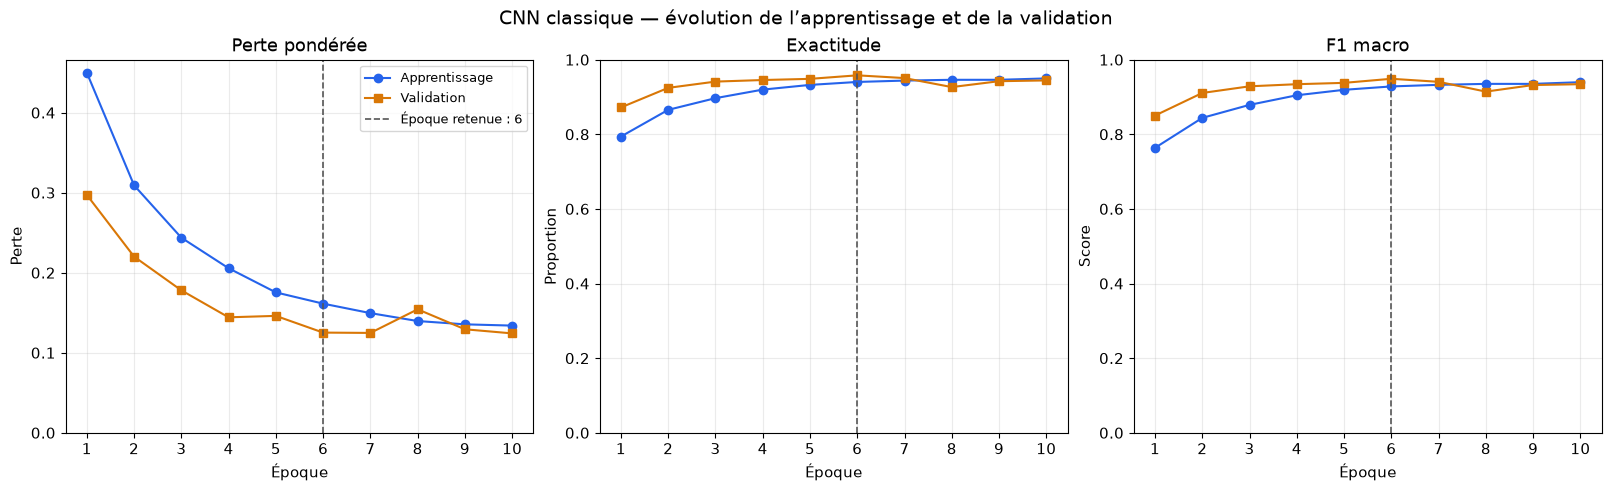

Figure PNG enregistrée : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\experiences\cnn_classique_20260917_125227_610127\figures\courbes_cnn_classique.png
Figure PDF enregistrée : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\experiences\cnn_classique_20260917_125227_610127\figures\courbes_cnn_classique.pdf


In [17]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DOSSIER_EXPERIENCE = Path(
    r"C:\Users\David KUNYIMA\OneDrive\Desktop"
    r"\Memoire_CNN_Attention\experiences"
    r"\cnn_classique_20260917_125227_610127"
)

resultats = pd.read_csv(
    DOSSIER_EXPERIENCE / "historique.csv"
).sort_values("epoque").reset_index(drop=True)

indice_meilleur = resultats["val_f1_macro"].idxmax()
epoque_retenue = int(resultats.loc[indice_meilleur, "epoque"])

DOSSIER_FIGURES = DOSSIER_EXPERIENCE / "figures"
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

graphiques = [
    ("perte", "Perte pondérée", "Perte"),
    ("exactitude", "Exactitude", "Proportion"),
    ("f1_macro", "F1 macro", "Score")
]

with plt.rc_context({"font.size": 11}):
    fig, axes = plt.subplots(
        1, 3, figsize=(16, 4.8), constrained_layout=True
    )

    for axe, (mesure, titre, etiquette_y) in zip(axes, graphiques):
        axe.plot(
            resultats["epoque"],
            resultats[f"train_{mesure}"],
            marker="o",
            color="#2563EB",
            label="Apprentissage"
        )

        axe.plot(
            resultats["epoque"],
            resultats[f"val_{mesure}"],
            marker="s",
            color="#D97706",
            label="Validation"
        )

        axe.axvline(
            epoque_retenue,
            color="#555555",
            linestyle="--",
            linewidth=1.2,
            label=f"Époque retenue : {epoque_retenue}"
        )

        axe.set_title(titre)
        axe.set_xlabel("Époque")
        axe.set_ylabel(etiquette_y)
        axe.set_xticks(resultats["epoque"])
        axe.grid(alpha=0.25)
        axe.set_axisbelow(True)

        if mesure == "perte":
            axe.set_ylim(bottom=0)
        else:
            # Échelle complète pour les proportions et les scores.
            axe.set_ylim(0, 1)

    axes[0].legend(fontsize=9)

    fig.suptitle(
        "CNN classique — évolution de l’apprentissage et de la validation",
        fontsize=14
    )

    chemin_png = DOSSIER_FIGURES / "courbes_cnn_classique.png"
    chemin_pdf = DOSSIER_FIGURES / "courbes_cnn_classique.pdf"

    fig.savefig(chemin_png, dpi=300, bbox_inches="tight")
    fig.savefig(chemin_pdf, bbox_inches="tight")

    plt.show()
    plt.close(fig)

print("Figure PNG enregistrée :", chemin_png)
print("Figure PDF enregistrée :", chemin_pdf)

In [18]:
import torch
from torch import nn

class AttentionCanaux(nn.Module):
    def __init__(self, canaux, reduction=16):
        super().__init__()

        dimension_interne = max(1, canaux // reduction)

        # Le même réseau traite les deux résumés.
        self.reseau_partage = nn.Sequential(
            nn.Conv2d(
                canaux, dimension_interne,
                kernel_size=1, bias=False
            ),
            nn.ReLU(),
            nn.Conv2d(
                dimension_interne, canaux,
                kernel_size=1, bias=False
            )
        )

    def forward(self, x):
        # Un résumé moyen et un résumé maximal par canal.
        moyenne = x.mean(dim=(2, 3), keepdim=True)
        maximum = x.amax(dim=(2, 3), keepdim=True)

        poids = torch.sigmoid(
            self.reseau_partage(moyenne)
            + self.reseau_partage(maximum)
        )

        return x * poids


class AttentionSpatiale(nn.Module):
    def __init__(self):
        super().__init__()

        self.convolution = nn.Conv2d(
            2, 1,
            kernel_size=7,
            padding=3,
            bias=False
        )

    def forward(self, x):
        # Résumer les canaux en deux cartes spatiales.
        moyenne = x.mean(dim=1, keepdim=True)
        maximum = x.amax(dim=1, keepdim=True)

        resume = torch.cat([moyenne, maximum], dim=1)
        poids = torch.sigmoid(self.convolution(resume))

        return x * poids


class CBAM(nn.Module):
    def __init__(self, canaux, reduction=16):
        super().__init__()

        self.attention_canaux = AttentionCanaux(
            canaux, reduction
        )
        self.attention_spatiale = AttentionSpatiale()

    def forward(self, x):
        x = self.attention_canaux(x)
        x = self.attention_spatiale(x)
        return x

print("Module CBAM défini.")

Module CBAM défini.


In [19]:
if "CNNClassique" not in globals():
    raise RuntimeError(
        "Exécute la cellule qui définit la classe CNNClassique."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "Exécute les cellules de préparation du Dataset."
    )


class CNNAvecCBAM(CNNClassique):
    def __init__(self):
        # Construire d'abord toute l'architecture du CNN classique.
        super().__init__()

        # Ajouter ensuite l'attention.
        self.cbam = CBAM(canaux=64, reduction=16)

    def forward(self, images):
        x = self.bloc1(images)
        x = self.bloc2(x)
        x = self.bloc3(x)

        x = self.cbam(x)

        x = self.reduction(x)
        return self.classificateur(x)


device_cbam = torch.device("cpu")

# Initialiser un nouveau modèle sans modifier le générateur
# aléatoire utilisé ailleurs dans le notebook.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(42)
    modele_cbam = CNNAvecCBAM().to(device_cbam)

# Le CNN classique était lui aussi initialisé avec la graine 42.
# Comme ses couches sont construites avant CBAM, les couches
# communes retrouvent la même initialisation dans cet environnement.

chargeur_verification_cbam = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

modele_cbam.eval()

with torch.random.fork_rng(devices=[]):
    images_cbam, _ = next(iter(chargeur_verification_cbam))

    with torch.no_grad():
        scores_cbam = modele_cbam(
            images_cbam.to(device_cbam)
        )

assert scores_cbam.shape == (len(images_cbam), 2)
assert torch.isfinite(scores_cbam).all()

nombre_total = sum(
    p.numel() for p in modele_cbam.parameters()
    if p.requires_grad
)

nombre_attention = sum(
    p.numel() for p in modele_cbam.cbam.parameters()
    if p.requires_grad
)

print("Dimensions en entrée :", images_cbam.shape)
print("Dimensions en sortie :", scores_cbam.shape)
print("Paramètres du CNN avec CBAM :", nombre_total)
print("Paramètres ajoutés par CBAM :", nombre_attention)
print("\nVérification du CNN avec CBAM réussie.")

modele_cbam.train();

Dimensions en entrée : torch.Size([16, 1, 224, 224])
Dimensions en sortie : torch.Size([16, 2])
Paramètres du CNN avec CBAM : 89636
Paramètres ajoutés par CBAM : 610

Vérification du CNN avec CBAM réussie.


In [20]:
import time
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def executer_epoque_modele(
    modele, chargeur, critere, appareil, optimiseur=None
):
    apprentissage = optimiseur is not None
    modele.train(apprentissage)

    somme_pertes = 0.0
    somme_poids = 0.0
    vraies_classes = []
    predictions = []

    description = (
        "CBAM — apprentissage"
        if apprentissage else "CBAM — validation"
    )

    for images, etiquettes in tqdm(chargeur, desc=description):
        images = images.to(appareil)
        etiquettes = etiquettes.to(appareil)

        if apprentissage:
            optimiseur.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(apprentissage):
            scores = modele(images)
            perte = critere(scores, etiquettes)

            if not torch.isfinite(perte).item():
                raise RuntimeError("Perte non finie détectée.")

            if apprentissage:
                perte.backward()
                optimiseur.step()

        poids_lot = critere.weight[etiquettes].sum().item()
        somme_pertes += perte.item() * poids_lot
        somme_poids += poids_lot

        predictions.extend(
            scores.detach().argmax(dim=1).cpu().tolist()
        )
        vraies_classes.extend(etiquettes.cpu().tolist())

    mesures = {
        "perte": somme_pertes / somme_poids,
        "exactitude": accuracy_score(vraies_classes, predictions),
        "precision_pneumonie": precision_score(
            vraies_classes, predictions,
            pos_label=1, zero_division=0
        ),
        "rappel_pneumonie": recall_score(
            vraies_classes, predictions,
            pos_label=1, zero_division=0
        ),
        "f1_pneumonie": f1_score(
            vraies_classes, predictions,
            pos_label=1, zero_division=0
        ),
        "f1_macro": f1_score(
            vraies_classes, predictions,
            labels=[0, 1], average="macro", zero_division=0
        )
    }

    matrice = confusion_matrix(
        vraies_classes, predictions, labels=[0, 1]
    )

    return mesures, matrice

c:\Users\David KUNYIMA\anaconda3\envs\memoire_cnn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [21]:
from datetime import datetime
from IPython.display import display

identifiant = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
DOSSIER_CBAM = (
    DOSSIER_PROJET / "experiences" / f"cnn_cbam_{identifiant}"
)
DOSSIER_CBAM.mkdir(parents=True, exist_ok=False)

# Nouvelle initialisation reproductible.
torch.manual_seed(42)
device_cbam = torch.device("cpu")
modele_cbam = CNNAvecCBAM().to(device_cbam)

# Recalculer les poids uniquement sur l'apprentissage.
effectifs_cbam = (
    train_dataset.tableau["classe"]
    .value_counts()
    .reindex(["NORMAL", "PNEUMONIA"], fill_value=0)
)

if (effectifs_cbam == 0).any():
    raise ValueError("Une classe est absente de l'apprentissage.")

poids_cbam = torch.tensor(
    [
        len(train_dataset) / (2 * effectifs_cbam["NORMAL"]),
        len(train_dataset) / (2 * effectifs_cbam["PNEUMONIA"])
    ],
    dtype=torch.float32,
    device=device_cbam
)

critere_cbam = torch.nn.CrossEntropyLoss(weight=poids_cbam)
optimiseur_cbam = torch.optim.Adam(
    modele_cbam.parameters(), lr=0.001
)

# Même ordre initial des images que pour le CNN classique.
train_loader_cbam, val_loader_cbam = creer_chargeurs(graine=42)
historique_cbam = []


def sauvegarder_cbam(nom_fichier, epoque):
    etat = {
        "epoque": epoque,
        "modele": modele_cbam.state_dict(),
        "optimiseur": optimiseur_cbam.state_dict(),
        "poids_classes": poids_cbam.cpu(),
        "historique": historique_cbam,
        "etat_aleatoire_torch": torch.get_rng_state(),
        "etat_generateur_train":
            train_loader_cbam.generator.get_state(),
        "dossier_repartition": str(DOSSIER_REPARTITION),
        "classes": CLASSES,
        "architecture": {
            "nom": "CNNAvecCBAM",
            "position_cbam": "apres_bloc3",
            "canaux": 64,
            "reduction": 16,
            "noyau_spatial": 7,
            "parametres": sum(
                p.numel() for p in modele_cbam.parameters()
                if p.requires_grad
            )
        },
        "pretraitement": {
            "taille": 224,
            "mode": "L",
            "redimensionnement": "padding noir, bilineaire, centre",
            "echelle_pixels": "division par 255",
            "augmentation": False
        },
        "taille_lot": train_loader_cbam.batch_size,
        "graine": 42,
        "epoque_finale_prevue": 10,
        "critere_selection": "val_f1_macro",
        "version_torch": str(torch.__version__)
    }

    destination = DOSSIER_CBAM / nom_fichier
    temporaire = destination.with_suffix(".tmp")
    torch.save(etat, temporaire)
    temporaire.replace(destination)


sauvegarder_cbam("initialisation.pt", epoque=0)

debut = time.perf_counter()

mesures_train_cbam, _ = executer_epoque_modele(
    modele_cbam,
    train_loader_cbam,
    critere_cbam,
    device_cbam,
    optimiseur=optimiseur_cbam
)

sauvegarder_cbam("apres_apprentissage_epoque_1.pt", epoque=1)

mesures_val_cbam, matrice_val_cbam = executer_epoque_modele(
    modele_cbam,
    val_loader_cbam,
    critere_cbam,
    device_cbam
)

duree_cbam = time.perf_counter() - debut

ligne = {"epoque": 1, "duree_secondes": duree_cbam}
ligne.update({
    f"train_{cle}": valeur
    for cle, valeur in mesures_train_cbam.items()
})
ligne.update({
    f"val_{cle}": valeur
    for cle, valeur in mesures_val_cbam.items()
})
historique_cbam.append(ligne)

sauvegarder_cbam("epoque_1.pt", epoque=1)

pd.DataFrame(historique_cbam).to_csv(
    DOSSIER_CBAM / "historique.csv", index=False
)

tableau_matrice = pd.DataFrame(
    matrice_val_cbam,
    index=["Vrai NORMAL", "Vrai PNEUMONIA"],
    columns=["Prédit NORMAL", "Prédit PNEUMONIA"]
)
tableau_matrice.to_csv(
    DOSSIER_CBAM / "matrice_val_epoque_1.csv"
)

display(pd.DataFrame(
    [mesures_train_cbam, mesures_val_cbam],
    index=["Apprentissage", "Validation"]
).round(4))

print("\nMatrice de confusion — validation :")
display(tableau_matrice)

print(f"\nDurée totale : {duree_cbam / 60:.2f} minutes")
print("Sauvegarde :", DOSSIER_CBAM / "epoque_1.pt")

CBAM — validation: 100%|██████████| 60/60 [00:40<00:00,  1.50it/s]


,perte,exactitude,precision_pneumonie,rappel_pneumonie,f1_pneumonie,f1_macro
Apprentissage,0.4500,0.7811,0.9087,0.7718,0.8347,0.7553
Validation,0.2906,0.8804,0.9553,0.8743,0.9130,0.8609



Matrice de confusion — validation :


,Prédit NORMAL,Prédit PNEUMONIA
Vrai NORMAL,241,28
Vrai PNEUMONIA,86,598



Durée totale : 3.80 minutes
Sauvegarde : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\experiences\cnn_cbam_20260917_160154_567863\epoque_1.pt


In [22]:
import time
import pandas as pd
from IPython.display import display

variables_requises = [
    "modele_cbam", "optimiseur_cbam", "critere_cbam",
    "device_cbam", "historique_cbam",
    "train_loader_cbam", "val_loader_cbam",
    "executer_epoque_modele", "sauvegarder_cbam",
    "DOSSIER_CBAM"
]

absentes = [
    nom for nom in variables_requises
    if nom not in globals()
]

if absentes:
    raise RuntimeError(
        "Il faut restaurer la session depuis la sauvegarde. "
        "Variables absentes : " + ", ".join(absentes)
    )

if not historique_cbam:
    raise RuntimeError("L'historique CBAM est vide.")

EPOQUE_FINALE_CBAM = 10
derniere_epoque = int(historique_cbam[-1]["epoque"])

for epoque in range(derniere_epoque + 1, EPOQUE_FINALE_CBAM + 1):
    print(f"\n===== CBAM — époque {epoque}/{EPOQUE_FINALE_CBAM} =====")
    debut = time.perf_counter()

    mesures_train_cbam, _ = executer_epoque_modele(
        modele_cbam,
        train_loader_cbam,
        critere_cbam,
        device_cbam,
        optimiseur=optimiseur_cbam
    )

    mesures_val_cbam, matrice_val_cbam = executer_epoque_modele(
        modele_cbam,
        val_loader_cbam,
        critere_cbam,
        device_cbam
    )

    duree = time.perf_counter() - debut

    ligne = {
        "epoque": epoque,
        "duree_secondes": duree
    }
    ligne.update({
        f"train_{cle}": valeur
        for cle, valeur in mesures_train_cbam.items()
    })
    ligne.update({
        f"val_{cle}": valeur
        for cle, valeur in mesures_val_cbam.items()
    })
    historique_cbam.append(ligne)

    # Sauvegarde complète après chaque époque.
    sauvegarder_cbam(f"epoque_{epoque}.pt", epoque=epoque)

    pd.DataFrame(historique_cbam).to_csv(
        DOSSIER_CBAM / "historique.csv",
        index=False
    )

    pd.DataFrame(
        matrice_val_cbam,
        index=["Vrai NORMAL", "Vrai PNEUMONIA"],
        columns=["Prédit NORMAL", "Prédit PNEUMONIA"]
    ).to_csv(
        DOSSIER_CBAM / f"matrice_val_epoque_{epoque}.csv"
    )

    display(pd.DataFrame(
        [mesures_train_cbam, mesures_val_cbam],
        index=["Apprentissage", "Validation"]
    ).round(4))

    print(f"Durée : {duree / 60:.2f} minutes")

# En cas d'égalité, retenir la première époque.
meilleure_ligne_cbam = max(
    historique_cbam,
    key=lambda ligne: ligne["val_f1_macro"]
)
meilleure_epoque_cbam = int(meilleure_ligne_cbam["epoque"])

print("\nHistorique complet du CNN avec CBAM :")
display(pd.DataFrame(historique_cbam).round(4))

print("\nMeilleure époque selon le F1 macro :", meilleure_epoque_cbam)
print(
    "F1 macro de validation :",
    round(meilleure_ligne_cbam["val_f1_macro"], 4)
)
print(
    "Sauvegarde correspondante :",
    DOSSIER_CBAM / f"epoque_{meilleure_epoque_cbam}.pt"
)


===== CBAM — époque 2/10 =====


CBAM — validation: 100%|██████████| 60/60 [00:29<00:00,  2.06it/s]


,perte,exactitude,precision_pneumonie,rappel_pneumonie,f1_pneumonie,f1_macro
Apprentissage,0.3076,0.8776,0.9512,0.8739,0.9109,0.8577
Validation,0.2159,0.9056,0.9853,0.8816,0.9306,0.8915


Durée : 3.71 minutes

===== CBAM — époque 3/10 =====


CBAM — validation: 100%|██████████| 60/60 [00:33<00:00,  1.81it/s]


...

CBAM — validation: 100%|██████████| 60/60 [00:26<00:00,  2.23it/s]


,perte,exactitude,precision_pneumonie,rappel_pneumonie,f1_pneumonie,f1_macro
Apprentissage,0.1316,0.9439,0.9779,0.9430,0.9601,0.9328
Validation,0.1479,0.9528,0.9624,0.9722,0.9673,0.9413


Durée : 3.39 minutes

Historique complet du CNN avec CBAM :


,epoque,duree_secondes,train_perte,train_exactitude,train_precision_pneumonie,train_rappel_pneumonie,train_f1_pneumonie,train_f1_macro,val_perte,val_exactitude,val_precision_pneumonie,val_rappel_pneumonie,val_f1_pneumonie,val_f1_macro
0,1,227.8199,0.4500,0.7811,0.9087,0.7718,0.8347,0.7553,0.2906,0.8804,0.9553,0.8743,0.9130,0.8609
1,2,222.7045,0.3076,0.8776,0.9512,0.8739,0.9109,0.8577,0.2159,0.9056,0.9853,0.8816,0.9306,0.8915
2,3,226.1459,0.2374,0.9011,0.9564,0.9030,0.9289,0.8831,0.1809,0.9171,0.9903,0.8933,0.9393,0.9043
3,4,254.3459,0.2164,0.9124,0.9653,0.9103,0.9370,0.8965,0.1565,0.9433,0.9701,0.9503,0.9601,0.9311
4,5,241.1039,0.1856,0.9242,0.9699,0.9228,0.9458,0.9100,0.1443,0.9454,0.9907,0.9327,0.9608,0.9354
5,6,297.3954,0.1740,0.9292,0.9723,0.9276,0.9494,0.9158,0.1417,0.9507,0.9733,0.9576,0.9654,0.9399
6,7,264.9685,0.1625,0.9311,0.9734,0.9291,0.9507,0.9180,0.1256,0.9538,0.9863,0.9488,0.9672,0.9446
7,8,246.1236,0.1535,0.9429,0.9768,0.9427,0.9594,0.9316,0.1453,0.9465,0.9717,0.9532,0.9624,0.9349
8,9,205.2928,0.1461,0.9395,0.9748,0.9397,0.9570,0.9275,0.1162,0.9570,0.9864,0.9532,0.9695,0.9482
9,10,203.1035,0.1316,0.9439,0.9779,0.9430,0.9601,0.9328,0.1479,0.9528,0.9624,0.9722,0.9673,0.9413



Meilleure époque selon le F1 macro : 9
F1 macro de validation : 0.9482
Sauvegarde correspondante : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\experiences\cnn_cbam_20260917_160154_567863\epoque_9.pt


In [23]:
from pathlib import Path
import json
import shutil
import pandas as pd
from IPython.display import display

DOSSIER_CBAM = Path(
    r"C:\Users\David KUNYIMA\OneDrive\Desktop"
    r"\Memoire_CNN_Attention\experiences"
    r"\cnn_cbam_20260917_160154_567863"
)

# Utiliser les valeurs complètes enregistrées dans le CSV.
resultats_cbam = pd.read_csv(
    DOSSIER_CBAM / "historique.csv"
).sort_values("epoque").reset_index(drop=True)

# En cas d'égalité, retenir la première époque.
meilleure = resultats_cbam.loc[
    resultats_cbam["val_f1_macro"].idxmax()
]
epoque_retenue = int(meilleure["epoque"])

source = DOSSIER_CBAM / f"epoque_{epoque_retenue}.pt"
destination = DOSSIER_CBAM / "meilleur_cnn_cbam.pt"

if not source.is_file():
    raise FileNotFoundError(f"Sauvegarde introuvable : {source}")

# Copier la sauvegarde complète de l'époque sélectionnée.
shutil.copy2(source, destination)

selection = {
    "modele": "CNNAvecCBAM",
    "critere_selection": "maximum du F1 macro de validation",
    "epoque_retenue": epoque_retenue,
    "nombre_epoques_executees": int(resultats_cbam["epoque"].max()),
    "sauvegarde_source": source.name,
    "sauvegarde_retenue": destination.name,
    "mesures_validation": {
        colonne: float(meilleure[colonne])
        for colonne in resultats_cbam.columns
        if colonne.startswith("val_")
    }
}

with open(
    DOSSIER_CBAM / "selection_modele.json",
    "w",
    encoding="utf-8"
) as fichier:
    json.dump(selection, fichier, indent=2, ensure_ascii=False)

matrice_cbam = pd.read_csv(
    DOSSIER_CBAM / f"matrice_val_epoque_{epoque_retenue}.csv",
    index_col=0
)

print("Époque retenue :", epoque_retenue)
print("F1 macro validation :", round(meilleure["val_f1_macro"], 4))
print("Sauvegarde :", destination)

print("\nMatrice de confusion — CBAM retenu :")
display(matrice_cbam)

Époque retenue : 9
F1 macro validation : 0.9482
Sauvegarde : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\experiences\cnn_cbam_20260917_160154_567863\meilleur_cnn_cbam.pt

Matrice de confusion — CBAM retenu :


,Prédit NORMAL,Prédit PNEUMONIA
Vrai NORMAL,260,9
Vrai PNEUMONIA,32,652


In [ ]:
# PRÉPARATION AUTONOME DU TEST — exécuter cette cellule EN ENTIER.
# Fonctionne après un redémarrage du noyau, sans relancer l'entraînement.
# Les définitions ci-dessous reproduisent les architectures et le prétraitement
# utilisés plus haut pour créer les sauvegardes sélectionnées.
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from torch import nn
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader


DOSSIER_PROJET = Path(
    r"C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention"
)

DOSSIER_IMAGES = DOSSIER_PROJET / "archive" / "chest_xray"

DOSSIER_REPARTITION = (
    DOSSIER_PROJET
    / "repartitions"
    / "repartition_20260917_102959_713272"
)


TAILLE_IMAGE = 224
CLASSES = {"NORMAL": 0, "PNEUMONIA": 1}


def preparer_image(image):
    """Convertir en niveaux de gris et redimensionner avec bordures."""
    image_grise = image.convert("L")

    return ImageOps.pad(
        image_grise,
        size=(TAILLE_IMAGE, TAILLE_IMAGE),
        method=Image.Resampling.BILINEAR,
        color=0,
        centering=(0.5, 0.5)
    )


def image_vers_tenseur(image):
    # Niveaux de gris, redimensionnement et bordures.
    image_preparee = preparer_image(image)

    # Tableau de nombres décimaux entre 0 et 1.
    tableau = np.array(image_preparee, dtype=np.float32) / 255.0

    # Passage de [hauteur, largeur] à [canal, hauteur, largeur].
    return torch.from_numpy(tableau).unsqueeze(0)


class RadiographiesDataset(Dataset):
    def __init__(self, fichier_csv, dossier_images, transformation):
        self.tableau = pd.read_csv(fichier_csv).reset_index(drop=True)
        self.dossier_images = dossier_images
        self.transformation = transformation

        if not self.tableau["classe"].isin(CLASSES).all():
            raise ValueError("Une classe inconnue figure dans le fichier CSV.")

    def __len__(self):
        return len(self.tableau)

    def __getitem__(self, indice):
        ligne = self.tableau.iloc[indice]
        chemin = self.dossier_images / ligne["chemin_relatif"]

        with Image.open(chemin) as image:
            tenseur = self.transformation(image)

        etiquette = torch.tensor(
            CLASSES[ligne["classe"]],
            dtype=torch.long
        )

        return tenseur, etiquette


class CNNClassique(nn.Module):
    def __init__(self):
        super().__init__()

        self.bloc1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.bloc2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.bloc3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.reduction = nn.AdaptiveAvgPool2d((4, 4))

        self.classificateur = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(64, 2)
        )

    def forward(self, images):
        x = self.bloc1(images)
        x = self.bloc2(x)
        x = self.bloc3(x)
        x = self.reduction(x)
        return self.classificateur(x)


class AttentionCanaux(nn.Module):
    def __init__(self, canaux, reduction=16):
        super().__init__()

        dimension_interne = max(1, canaux // reduction)

        # Le même réseau traite les deux résumés.
        self.reseau_partage = nn.Sequential(
            nn.Conv2d(
                canaux, dimension_interne,
                kernel_size=1, bias=False
            ),
            nn.ReLU(),
            nn.Conv2d(
                dimension_interne, canaux,
                kernel_size=1, bias=False
            )
        )

    def forward(self, x):
        # Un résumé moyen et un résumé maximal par canal.
        moyenne = x.mean(dim=(2, 3), keepdim=True)
        maximum = x.amax(dim=(2, 3), keepdim=True)

        poids = torch.sigmoid(
            self.reseau_partage(moyenne)
            + self.reseau_partage(maximum)
        )

        return x * poids


class AttentionSpatiale(nn.Module):
    def __init__(self):
        super().__init__()

        self.convolution = nn.Conv2d(
            2, 1,
            kernel_size=7,
            padding=3,
            bias=False
        )

    def forward(self, x):
        # Résumer les canaux en deux cartes spatiales.
        moyenne = x.mean(dim=1, keepdim=True)
        maximum = x.amax(dim=1, keepdim=True)

        resume = torch.cat([moyenne, maximum], dim=1)
        poids = torch.sigmoid(self.convolution(resume))

        return x * poids


class CBAM(nn.Module):
    def __init__(self, canaux, reduction=16):
        super().__init__()

        self.attention_canaux = AttentionCanaux(
            canaux, reduction
        )
        self.attention_spatiale = AttentionSpatiale()

    def forward(self, x):
        x = self.attention_canaux(x)
        x = self.attention_spatiale(x)
        return x


class CNNAvecCBAM(CNNClassique):
    def __init__(self):
        # Construire d'abord toute l'architecture du CNN classique.
        super().__init__()

        # Ajouter ensuite l'attention.
        self.cbam = CBAM(canaux=64, reduction=16)

    def forward(self, images):
        x = self.bloc1(images)
        x = self.bloc2(x)
        x = self.bloc3(x)

        x = self.cbam(x)

        x = self.reduction(x)
        return self.classificateur(x)


DOSSIER_CLASSIQUE = (
    DOSSIER_PROJET / "experiences"
    / "cnn_classique_20260917_125227_610127"
)
DOSSIER_CBAM = (
    DOSSIER_PROJET / "experiences"
    / "cnn_cbam_20260917_160154_567863"
)

appareil_test = torch.device("cpu")

etat_classique = torch.load(
    DOSSIER_CLASSIQUE / "meilleur_cnn_classique.pt",
    map_location="cpu",
    weights_only=True
)
etat_cbam = torch.load(
    DOSSIER_CBAM / "meilleur_cnn_cbam.pt",
    map_location="cpu",
    weights_only=True
)

# Vérifier les sauvegardes et leur configuration.
assert etat_classique["epoque"] == 6
assert etat_cbam["epoque"] == 9

for etat in [etat_classique, etat_cbam]:
    assert etat["classes"] == {"NORMAL": 0, "PNEUMONIA": 1}
    assert (
        Path(etat["dossier_repartition"]).resolve()
        == DOSSIER_REPARTITION.resolve()
    )

assert etat_classique["pretraitement"] == etat_cbam["pretraitement"]
assert torch.equal(
    etat_classique["poids_classes"],
    etat_cbam["poids_classes"]
)

test_dataset = RadiographiesDataset(
    DOSSIER_REPARTITION / "test.csv",
    DOSSIER_IMAGES,
    image_vers_tenseur
)

effectifs_test = test_dataset.tableau["classe"].value_counts()
assert len(test_dataset) == 618
assert effectifs_test["NORMAL"] == 231
assert effectifs_test["PNEUMONIA"] == 387

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

# Objets réservés à l'évaluation.
# Conserver aussi l'état du générateur aléatoire.
with torch.random.fork_rng(devices=[]):
    modeles_test = {
        "CNN_classique": CNNClassique().to(appareil_test),
        "CNN_CBAM": CNNAvecCBAM().to(appareil_test)
    }

modeles_test["CNN_classique"].load_state_dict(
    etat_classique["modele"], strict=True
)
modeles_test["CNN_CBAM"].load_state_dict(
    etat_cbam["modele"], strict=True
)

for modele in modeles_test.values():
    modele.eval()

identifiant_test = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
DOSSIER_TEST = (
    DOSSIER_PROJET / "evaluations" / f"test_{identifiant_test}"
)
DOSSIER_TEST.mkdir(parents=True, exist_ok=False)

print("Images de test :", len(test_dataset))
print("CNN classique chargé : époque", etat_classique["epoque"])
print("CNN avec CBAM chargé : époque", etat_cbam["epoque"])
print("Préparation du test terminée.")

In [25]:
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)
from IPython.display import display

def evaluer_sur_test(modele, nom):
    vraies_classes = []
    predictions = []
    probabilites = []

    modele.eval()

    with torch.inference_mode():
        for images, etiquettes in tqdm(test_loader, desc=nom):
            scores = modele(images.to(appareil_test))

            if not torch.isfinite(scores).all().item():
                raise RuntimeError("Scores non finis détectés.")

            predictions.extend(
                scores.argmax(dim=1).cpu().tolist()
            )
            probabilites.extend(
                torch.softmax(scores, dim=1)[:, 1].cpu().tolist()
            )
            vraies_classes.extend(etiquettes.tolist())

    matrice = confusion_matrix(
        vraies_classes, predictions, labels=[0, 1]
    )
    vn, fp, fn, vp = matrice.ravel()

    mesures = {
        "modele": nom,
        "exactitude": accuracy_score(vraies_classes, predictions),
        "precision_pneumonie": precision_score(
            vraies_classes, predictions, zero_division=0
        ),
        "rappel_pneumonie": recall_score(
            vraies_classes, predictions, zero_division=0
        ),
        "specificite_NORMAL": vn / (vn + fp),
        "f1_pneumonie": f1_score(
            vraies_classes, predictions, zero_division=0
        ),
        "f1_macro": f1_score(
            vraies_classes, predictions,
            labels=[0, 1], average="macro", zero_division=0
        ),
        "auc_roc": roc_auc_score(vraies_classes, probabilites),
        "faux_positifs": int(fp),
        "faux_negatifs": int(fn)
    }

    # shuffle=False conserve l'ordre des lignes du Dataset.
    details = test_dataset.tableau[
        ["chemin_relatif", "classe"]
    ].copy()

    details["vraie_etiquette"] = vraies_classes
    details["prediction"] = predictions
    details["probabilite_pneumonie"] = probabilites
    details["prediction_correcte"] = (
        details["vraie_etiquette"] == details["prediction"]
    )

    details.to_csv(
        DOSSIER_TEST / f"predictions_{nom}.csv",
        index=False,
        encoding="utf-8-sig"
    )

    tableau_matrice = pd.DataFrame(
        matrice,
        index=["Vrai NORMAL", "Vrai PNEUMONIA"],
        columns=["Prédit NORMAL", "Prédit PNEUMONIA"]
    )
    tableau_matrice.to_csv(
        DOSSIER_TEST / f"matrice_{nom}.csv"
    )

    print(f"\nMatrice de confusion — {nom}")
    display(tableau_matrice)

    return mesures


resultats_test = []

for nom, modele in modeles_test.items():
    resultats_test.append(evaluer_sur_test(modele, nom))

comparaison_test = pd.DataFrame(resultats_test).set_index("modele")

comparaison_test.to_csv(
    DOSSIER_TEST / "comparaison_test.csv",
    encoding="utf-8-sig"
)

print("\nComparaison sur l'ensemble de test :")
display(comparaison_test.round(4))

print("\nRésultats enregistrés dans :", DOSSIER_TEST)

CNN_classique: 100%|██████████| 39/39 [00:16<00:00,  2.32it/s]


Matrice de confusion — CNN_classique


,Prédit NORMAL,Prédit PNEUMONIA
Vrai NORMAL,111,120
Vrai PNEUMONIA,7,380


CNN_CBAM: 100%|██████████| 39/39 [00:18<00:00,  2.15it/s]


Matrice de confusion — CNN_CBAM


,Prédit NORMAL,Prédit PNEUMONIA
Vrai NORMAL,98,133
Vrai PNEUMONIA,10,377



Comparaison sur l'ensemble de test :


,exactitude,precision_pneumonie,rappel_pneumonie,specificite_NORMAL,f1_pneumonie,f1_macro,auc_roc,faux_positifs,faux_negatifs
modele,,,,,,,,,
CNN_classique,0.7945,0.7600,0.9819,0.4805,0.8568,0.7465,0.9095,120,7
CNN_CBAM,0.7686,0.7392,0.9742,0.4242,0.8406,0.7094,0.9058,133,10



Résultats enregistrés dans : C:\Users\David KUNYIMA\OneDrive\Desktop\Memoire_CNN_Attention\evaluations\test_20260917_173429_491252
